# 59 · 연속 행동의 DDPG·TD3·SAC

📎 **이번 질문** · 왼쪽·오른쪽 버튼 대신 힘의 크기를 연속적으로 고르려면 actor와 Q를 어떻게 연결할까요?

준비물: 12 Gaussian, 25 재매개화, 55 replay·target Q, 57 actor–critic, 03·04 MLP·Adam. NumPy·CPU float64만 사용하며 다른 노트북 실행 상태나 다운로드에 의존하지 않습니다. 원점으로 되돌아오는 작은 장치의 합성 제어 환경로 수식부터 실제 학습까지 연결합니다.

| 표시 | 뜻 | 읽는 법 |
|---|---|---|
| 🔑 | 핵심 | 축과 기울기 경로를 씁니다 |
| 🔍 | 확인 | 그림·손계산·독립 평가를 대조합니다 |
| 📎 | 참고 | 처음 나온 용어·관용구를 풀이합니다 |
| ✏️ | 연습 | 한두 줄을 채우고 검사합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. 연속 행동은 actor가 만들고 Q는 그 행동의 장기 보상을 근사합니다.
2. TD3의 두 Q·타깃 잡음·지연 갱신과 SAC의 확률정책·entropy는 실제 target과 gradient를 바꿉니다.
3. 수집·종료·target·평가 분모를 고정해 실제 다단계 제어 결과를 검사합니다.

[학습 경로](../../docs/CURRICULUM.md) · [그림 보조 코드](../../src/utils/continuous_control_plots.py)

In [1]:
# 준비 셀: 그림과 독립 미분 검산 도구입니다.
import sys
from pathlib import Path
import numpy as np
project_root = next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots,run_check
from src.utils.gradcheck import numerical_gradient,rel_error
from src.utils.continuous_control_plots import plot_panels,plot_curves,plot_trajectories
setup_plots()

from time import perf_counter

## 🔑 1. 연속 힘으로 상태를 원점에 가깝게 만듭니다

**이 절에서 가져갈 것:** actor의 행동 범위와 환경의 장기 보상 목적을 먼저 적습니다.

장치의 위치 s를 원점0에 유지하려고 힘 a를 가합니다. a는−1부터1 사이의 실수입니다. 환경은
$$s_{t+1}=.85s_t+.5a_t+\epsilon_t,\quad \epsilon_t\sim N(0,.03^2),\quad r_t=-(s_{t+1}^2+.05a_t^2)$$
이며 할인율 γ=.95입니다. 보상이 더 크다는 것은 원점 오차와 힘의 비용이 더 작다는 뜻입니다. 행동을 아무렇게나 크게 쓰는 것이 목적이 아닙니다.

> **용어**
> - **연속 행동(continuous action)**은 정해진 몇 개 선택지 대신 범위 안 실수를 고르는 것입니다.
> - **actor**는 상태에서 행동 또는 행동 분포를 만드는 모델입니다.
> - **critic Q(s,a)**는 그 상태에서 a를 쓴 뒤 정책을 따를 때의 할인 보상을 근사합니다.
> - **결정론 정책**은 같은 상태에 항상 같은 행동을 냅니다. 여기서는 $a=\tanh f_\theta(s)$입니다.

상태·행동·보상은 각각 `(N,1)` 열입니다. actor는1→8→1, critic은2→12→1 tanh MLP입니다. 공통 MLP $H=\tanh(XW+b)$, $Y=HV+c$에서 $dU=(GV^T)\odot(1-H^2)$, $dW=X^TdU$, $db=\sum dU$, $dV=H^TG$, $dc=\sum G$, $dX=dUW^T$입니다. critic의 입력 두 열은 `[s,a]`입니다.

> **코드** · `np.concatenate([S,A],axis=1)`는 상태·행동을 열로 붙입니다. 이름별 파라미터 사전은 W,b,V,c를 저장합니다. `[:,None]`은 표본을 열로 만듭니다.

In [2]:
states=np.array([[1.],[1.],[1.]])
actions=np.array([[-1.],[0.],[1.]])
next_states=.85*states+.5*actions
rewards=-(next_states**2+.05*actions**2)
transition=np.concatenate([states,actions,next_states,rewards],axis=1)

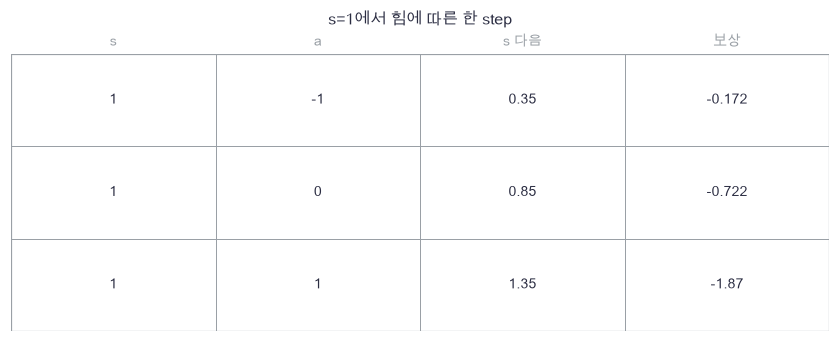

In [3]:
plot_panels([transition],['s=1에서 힘에 따른 한 step'],[['s','a','s 다음','보상']])

🔍 **확인** · 이 한 step에서는 음의 힘이 원점으로 되돌립니다. 한 step의 가장 좋은 행동과 장기 정책은 별개이며 다음 상태의 보상도 고려해야 합니다.

In [4]:
def control_step(state,action,noise):
    """s′=.85s+.5a+noise와 r=−(s′²+.05a²). 실제 종료 없는 continuing 제어입니다."""
    next_state=.85*state+.5*action+noise
    reward=-(next_state**2+.05*action**2)
    return next_state,reward

In [5]:
def init_mlp(din,dout,seed,hidden=8):
    """tanh 은닉층 하나와 선형 출력층의 모든 배열을 초기화합니다."""
    rng=np.random.default_rng(seed)
    return {'W':rng.normal(0,.3,(din,hidden)),'b':np.zeros(hidden),
            'V':rng.normal(0,.15,(hidden,dout)),'c':np.zeros(dout)}

In [6]:
def mlp_forward(X,p):
    """H=tanh(XW+b), Y=HV+c. 입력:(N,D) → 출력:(N,K),cache."""
    H=np.tanh(X@p['W']+p['b'])
    return H@p['V']+p['c'],(X,H)

In [7]:
def mlp_backward(G,cache,p):
    """모든 파라미터·입력의 연쇄법칙입니다. G는 출력과 같은 shape입니다."""
    X,H=cache
    dU=(G@p['V'].T)*(1-H**2)
    grads={'V':H.T@G,'c':G.sum(axis=0),'W':X.T@dU,'b':dU.sum(axis=0)}
    return grads,dU@p['W'].T

In [8]:
# 쓰는 것: actions (1절) · control_step (1절) · rewards (1절) · states (1절)
loop_next=[]
loop_reward=[]
for s,a in zip(states[:,0],actions[:,0]):
    ns,r=control_step(s,a,0.)
    loop_next.append(ns)
    loop_reward.append(r)
np.testing.assert_allclose(loop_next,[.35,.85,1.35])  # 검산: 손계산 전이
np.testing.assert_allclose(loop_reward,rewards[:,0])  # 검산: 반복문 = 벡터화 보상
assert np.all(rewards<=0), '제곱 비용의 음수인 보상은0 이하여야 합니다'
print('환경 전이·행동 비용의 손계산을 확인했습니다.')

환경 전이·행동 비용의 손계산을 확인했습니다.


### ✏️ 연습 1 · 연속 행동의 다음 상태

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

잡음0일 때 벡터 상태·행동의 다음 상태를 계산하세요.

In [9]:
def exercise_continuous_step(s,a):
    """잡음0일 때 벡터 상태·행동의 다음 상태를 계산하세요."""

    ### 구현할 내용: 잡음0일 때 벡터 상태·행동의 다음 상태를 계산하세요.
    raise NotImplementedError
    return next_s

In [10]:
def check_continuous_step(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([1.,-1.]),np.array([-1.,1.])),[.35,-.35])  # 검산: 잡음0의 대칭 전이
    print("연습 1: 독립 기준값과 일치합니다.")

run_check(check_continuous_step,exercise_continuous_step,hint="잡음0일 때 벡터 상태·행동의 다음 상태를 계산하세요.")

☐ exercise_continuous_step: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 잡음0일 때 벡터 상태·행동의 다음 상태를 계산하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
next_s = .85*s+.5*a
```

</details>

## 🔑 2. Gaussian을 tanh로 보내고 밀도를 보정합니다

**이 절에서 가져갈 것:** 행동의 범위를 제한하면 로그 밀도에도 Jacobian 보정이 필요합니다.

SAC는 같은 상태에서도 여러 힘을 시도하는 확률 정책을 씁니다. MLP의 두 출력은 평균 μ와 scale 원점수 ρ입니다.

> **용어**
> - **재매개화(reparameterization)**는 고정 표준정규 잡음 ξ를 이용해 $u=\mu+\sigma\xi$로 표본을 만드는 방법입니다.
> - **entropy**는 분포의 퍼짐을 측정합니다. 여기서는 `−logπ`의 기대값으로 보상을 확장합니다.
> - **log-Jacobian**은 tanh가 부피를 줄이는 정도의 로그이며 밀도 보정에 들어갑니다.

$$\ell=\log\sigma=-1+.5\tanh\rho,\quad u=\mu+e^\ell\xi,\quad a=\tanh u,$$
$$\log\pi(a|s)=-\tfrac12\xi^2-\ell-\tfrac12\log(2\pi)-\log(1-\tanh^2u).$$

logσ 범위는(−1.5,−.5)입니다. 이 작은 실험의 탐색 범위 제한이며 원문 전체 설정은 아닙니다. 안정식 `log(1−tanh²u)=2*(log2−u−logaddexp(0,−2u))`를 써 포화에서도 로그0을 피합니다. tanh 이후 행동을 추가로 clip하면 분포가 바뀌므로 SAC 학습에서는 clip하지 않습니다. 유한 정밀도에서 극단 u의 tanh가±1로 반올림될 수는 있습니다.

고정 ξ의 전체 미분은 $d_u=d_a(1-a^2)+2a\,d_{\log\pi}$, $d_\mu=d_u$, $d_\ell=d_u\sigma\xi-d_{\log\pi}$, $d_\rho=.5(1-\tanh^2\rho)d_\ell$입니다. `−logσ` 직접 경로를 빠뜨리면 SAC gradient가 틀립니다.

> **코드** · `logaddexp`는 큰 지수의 overflow를 피합니다. `noise`는 표준정규 배열이며 수치미분 중 다시 뽑지 않습니다. deterministic 경로의 logprob는 `None`입니다. 결정론 행동에 연속 확률밀도를 붙이지 않습니다.

In [11]:
u_demo=np.array([[-1.],[0.],[1.]])
a_demo=np.tanh(u_demo)
logjac_demo=2*(np.log(2.)-u_demo-np.logaddexp(0.,-2*u_demo))
normal_log=-.5*u_demo**2-.5*np.log(2*np.pi)
transformed_log=normal_log-logjac_demo

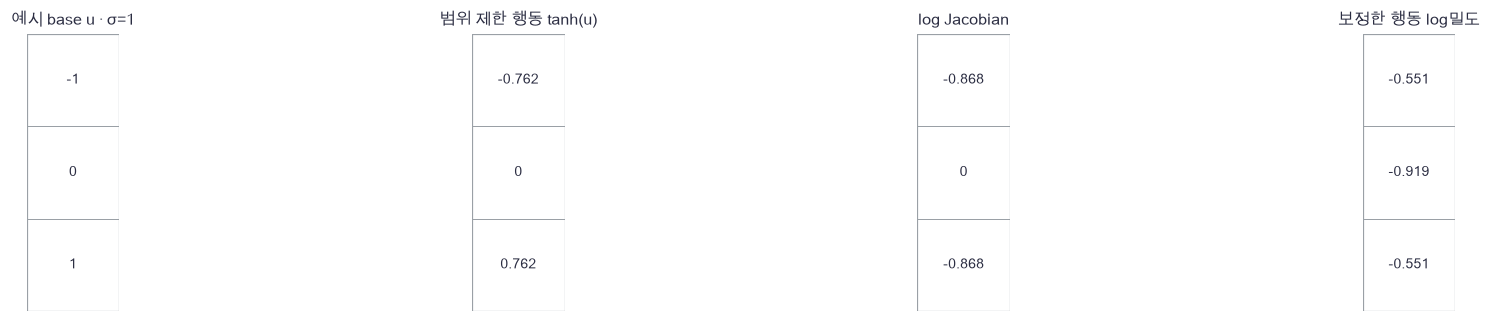

In [12]:
plot_panels([u_demo,a_demo,logjac_demo,transformed_log],['예시 base u · σ=1','범위 제한 행동 tanh(u)','log Jacobian','보정한 행동 log밀도'])

🔍 **확인** · 그림은 일반 변수변환을 보는 σ=1 예시이며 실제 정책은 위의 bounded logσ를 씁니다. tanh가 눌러 모은 구간에서는 밀도가 높아질 수 있습니다.

In [13]:
def policy_forward(S,p,noise,stochastic=False):
    """결정론 tanh 또는 재매개화한 Gaussian-tanh 정책. S,noise:(N,1)."""
    # 쓰는 것: mlp_forward (1절)
    raw,cache=mlp_forward(S,p)
    if not stochastic:
        action=np.tanh(raw)
        return action,None,(cache,action,False,None,None,None)
    mean=raw[:,:1]
    bounded=np.tanh(raw[:,1:2])
    logstd=-1.+.5*bounded
    std=np.exp(logstd)
    u=mean+std*noise
    action=np.tanh(u)
    logjac=2*(np.log(2.)-u-np.logaddexp(0.,-2*u))
    logprob=-.5*noise**2-logstd-.5*np.log(2*np.pi)-logjac
    return action,logprob,(cache,action,True,std,noise,bounded)

In [14]:
def policy_backward(daction,dlogprob,cache,p):
    """고정 noise에서 행동·log density의 두 경로를 모두 미분합니다."""
    # 쓰는 것: mlp_backward (1절)
    network,action,stochastic,std,noise,bounded=cache
    du=daction*(1-action**2)
    if not stochastic:
        return mlp_backward(du,network,p)
    du+=2*action*dlogprob
    dlogstd=du*std*noise-dlogprob
    draw=np.concatenate([du,.5*(1-bounded**2)*dlogstd],axis=1)
    return mlp_backward(draw,network,p)

In [15]:
action_grid=np.linspace(-1+1e-6,1-1e-6,20001)
base_u=np.arctanh(action_grid)
logstd=-1.
log_density=-.5*(base_u/np.exp(logstd))**2-logstd-.5*np.log(2*np.pi)-np.log1p(-action_grid**2)
mass=np.trapezoid(np.exp(log_density),action_grid)
np.testing.assert_allclose(mass,1.,atol=2e-5)  # 검산: μ0/logσ−1 행동밀도 수치적분
large_u=np.array([-30.,0.,30.])
large_logjac=2*(np.log(2.)-large_u-np.logaddexp(0.,-2*large_u))
assert np.isfinite(large_logjac).all(), '포화 영역에서도 log Jacobian이 유한해야 합니다'
print('행동밀도 적분',mass,'· 포화 logJacobian',large_logjac)

행동밀도 적분 1.0 · 포화 logJacobian [-58.61370564   0.         -58.61370564]


### ✏️ 연습 2 · tanh의 로그 밀도 보정

base Gaussian log밀도에서 tanh log Jacobian을 빼세요.

In [16]:
def exercise_jacobian(normal_logprob,u):
    """base Gaussian log밀도에서 tanh log Jacobian을 빼세요."""

    ### 구현할 내용: base Gaussian log밀도에서 tanh log Jacobian을 빼세요.
    raise NotImplementedError
    return logprob

In [17]:
def check_jacobian(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([-1.]),np.array([0.])),[-1.])  # 검산: u0의 Jacobian1
    np.testing.assert_allclose(candidate(np.array([-1.]),np.array([np.arctanh(.5)])),[-1-np.log(.75)])  # 검산: a=.5의 Jacobian.75
    print("연습 2: 독립 기준값과 일치합니다.")

run_check(check_jacobian,exercise_jacobian,hint="base Gaussian log밀도에서 tanh log Jacobian을 빼세요.")

☐ exercise_jacobian: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: base Gaussian log밀도에서 tanh log Jacobian을 빼세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
logprob = normal_logprob-2*(np.log(2.)-u-np.logaddexp(0.,-2*u))
```

</details>

## 🔑 3. 두 Q·타깃과 actor의 미분을 연결합니다

**이 절에서 가져갈 것:** critic target은 고정하고 actor는 Q의 행동 입력 경로를 따라 학습합니다.

critic은 replay의 행동을 평가하고 actor는 현재 상태에서 더 좋은 행동을 찾습니다. 갱신할 대상이 다릅니다.

> **용어** · **TD target y**는 현재 Q가 맞힐 한 step 보상과 다음 Q의 합입니다. **target network**는 이 값을 안정시키기 위해 느리게 옮기는 별도 파라미터입니다. **두 Q의 최소값**은 과대평가를 줄이는 장치이며 항상 참 Q의 하한이라는 보장은 없습니다.

DDPG: $y=r+\gamma(1-d)\bar Q(s',\bar\mu(s'))$, $J_\pi=-E[Q(s,\mu(s))]$.
TD3: $a'=\operatorname{clip}(\bar\mu(s')+\operatorname{clip}(.2\xi,-.5,.5),-1,1)$, $y=r+\gamma(1-d)\min_j\bar Q_j(s',a')$. actor는 **Q1**을 최대화합니다.
SAC: $a'\sim\pi_\theta(\cdot|s')$, $y=r+\gamma(1-d)[\min_j\bar Q_j(s',a')-\alpha\log\pi_\theta(a'|s')]$, $J_\pi=E[\alpha\log\pi_\theta(a|s)-\min_jQ_j(s,a)]$.

여기서 d는 실제 종료입니다. critic별 $L_Q=\frac1{2N}\sum(Q-y)^2$, $dQ=(Q-y)/N$이고 y를 역전파하지 않습니다. actor에서는 critic **파라미터를 고정**하지만 $\partial Q/\partial a$는 사용합니다. min의 동률은 첫 Q를 택하는 부분기울기이며 수치 검산에서는 충분한 차이를 둡니다. α=.1은 미리 고정하며 자동 entropy 계수 학습은 이 예제의 범위 밖입니다.

SAC는 별도 V 모델 없이 두 target Q를 쓰는 후속 알고리즘 형태입니다. 재매개화 잡음·target 값·critic 파라미터를 고정한 채 actor의 모든 파라미터와 상태 입력을 차분합니다. 상태 미분에는 Q가 s를 직접 읽는 경로도 더합니다.

In [18]:
rewards_demo=np.array([[-1.],[-1.]])
terminal_demo=np.array([[1.],[0.]])
q_pair=np.array([[2.,3.],[4.,1.]])
target_demo=rewards_demo+.95*(1-terminal_demo)*q_pair.min(axis=1,keepdims=True)
delay_table=np.array([[1,1,0],[2,1,1],[3,1,0],[4,1,1]])

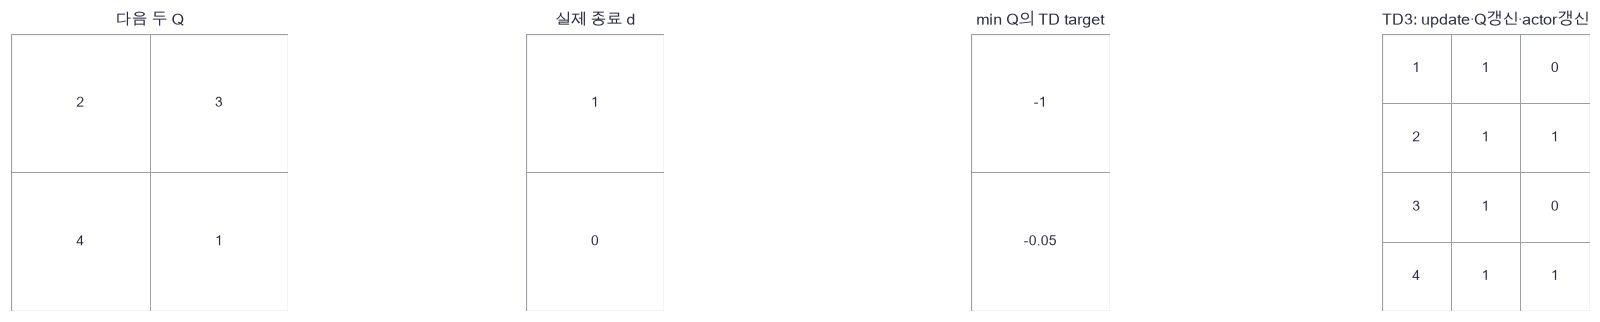

In [19]:
plot_panels([q_pair,terminal_demo,target_demo,delay_table],['다음 두 Q','실제 종료 d','min Q의 TD target','TD3: update·Q갱신·actor갱신'])

🔍 **확인** · 첫 전이는 종료되어 y=−1입니다. 둘째는 y=−1+.95×1=−.05입니다. TD3의 actor와 target은 Q 두 번 갱신마다 한 번 움직입니다.

In [20]:
def critic_loss(S,A,target,p):
    """고정 TD target의 반 평균제곱오차와 critic 전체 미분입니다."""
    # 쓰는 것: mlp_backward (1절) · mlp_forward (1절)
    Q,cache=mlp_forward(np.concatenate([S,A],axis=1),p)
    residual=Q-target
    grads,dinputs=mlp_backward(residual/len(S),cache,p)
    return .5*np.mean(residual**2),grads,dinputs

In [21]:
def actor_loss(S,actor,critics,noise,method,alpha=.1):
    """고정 critic에서 DDPG/TD3의 −Q1 또는 SAC의 αlogπ−minQ를 미분합니다."""
    # 쓰는 것: mlp_backward (1절) · mlp_forward (1절) · policy_backward (2절) · policy_forward (2절)
    # 1. critic의 입력 경로만 actor에 전달합니다.
    action,logprob,cache=policy_forward(S,actor,noise,method=='SAC')
    qa=[]
    caches=[]
    for critic in critics:
        Q,qcache=mlp_forward(np.concatenate([S,action],axis=1),critic)
        qa.append(Q)
        caches.append(qcache)
    choice=np.argmin(np.concatenate(qa,axis=1),axis=1) if method=='SAC' else np.zeros(len(S),dtype=int)
    selected=np.concatenate(qa,axis=1)[np.arange(len(S)),choice]
    dinputs=np.zeros((len(S),2))
    for j,(critic,qcache) in enumerate(zip(critics,caches)):
        upstream=-(choice==j).astype(float)[:,None]/len(S)
        _,dx=mlp_backward(upstream,qcache,critic)
        dinputs+=dx
    # 2. 직접 상태 경로와 정책을 통과한 상태 경로도 합합니다.
    dlog=np.full((len(S),1),alpha/len(S)) if method=='SAC' else np.zeros((len(S),1))
    grads,dstate=policy_backward(dinputs[:,1:2],dlog,cache,actor)
    loss=-selected.mean()
    if method=='SAC':
        loss+=alpha*logprob.mean()
    return loss,grads,dstate+dinputs[:,:1]

In [22]:
def td_target(reward,next_S,terminal,actor,target_actor,target_critics,noise,method,gamma=.95,alpha=.1):
    """종료만 bootstrap을 끄며 학습 구간 truncation은 끄지 않습니다. 결과는 고정 target입니다."""
    # 쓰는 것: mlp_forward (1절) · policy_forward (2절)
    if method=='SAC':
        action,logprob,_=policy_forward(next_S,actor,noise,True)
    else:
        action,_,_=policy_forward(next_S,target_actor,noise,False)
        if method=='TD3':
            action=np.clip(action+np.clip(.2*noise,-.5,.5),-1.,1.)
    values=[]
    for critic in target_critics:
        Q,_=mlp_forward(np.concatenate([next_S,action],axis=1),critic)
        values.append(Q)
    bootstrap=np.min(np.concatenate(values,axis=1),axis=1,keepdims=True)
    if method=='SAC':
        bootstrap-=alpha*logprob
    return reward+gamma*(1-terminal)*bootstrap

In [23]:
# 쓰는 것: init_mlp (1절) · mlp_forward (1절) · policy_forward (2절)
probe_actor=init_mlp(1,2,590,3)
probe_q1=init_mlp(2,1,591,3)
probe_q2=init_mlp(2,1,592,3)
probe_q1['c']-=.5
probe_s=np.array([[-.4],[.7]])
probe_noise=np.array([[.3],[-.6]])
probe_action,_,_=policy_forward(probe_s,probe_actor,probe_noise,True)
q1,_=mlp_forward(np.concatenate([probe_s,probe_action],axis=1),probe_q1)
q2,_=mlp_forward(np.concatenate([probe_s,probe_action],axis=1),probe_q2)
assert np.min(np.abs(q1-q2))>.1, 'min branch는 수치미분 중 뒤집히지 않을 여유가 있어야 합니다'
_,actor_grad,state_grad=actor_loss(probe_s,probe_actor,[probe_q1,probe_q2],probe_noise,'SAC')

In [24]:
def actor_objective():
    """잡음과 두 critic을 고정한 SAC actor 목적입니다."""
    return actor_loss(probe_s,probe_actor,[probe_q1,probe_q2],probe_noise,'SAC')[0]

In [25]:
actor_errors=[]
for key in probe_actor:
    numeric=numerical_gradient(actor_objective,probe_actor[key])
    np.testing.assert_allclose(actor_grad[key],numeric,atol=2e-8,rtol=3e-5)  # 검산: μ·logσ 경로의 모든 actor 파라미터
    actor_errors.append(np.max(np.abs(actor_grad[key]-numeric)))
np.testing.assert_allclose(state_grad,numerical_gradient(actor_objective,probe_s),atol=2e-8)  # 검산: Q 직접상태+정책상태 경로
print('SAC 전체 actor 최대 절대오차',max(actor_errors))

SAC 전체 actor 최대 절대오차 5.7884595987961474e-11


In [26]:
# 쓰는 것: critic_loss (3절)
fixed_y=np.array([[-.2],[.4]])
probe_qa=np.array([[.1],[-.2]])
critic_gradients=[]
for critic in [probe_q1,probe_q2]:
    _,grads,inputs=critic_loss(probe_s,probe_qa,fixed_y,critic)
    critic_gradients.append((grads,inputs))

In [27]:
def critic_objective():
    """현재 검산 critic의 고정 TD target 반 MSE입니다."""
    # 쓰는 것: critic_loss (3절) · probe_s (3절)
    return critic_loss(probe_s,probe_qa,fixed_y,current_critic)[0]

In [28]:
# 쓰는 것: probe_q1 (3절) · probe_q2 (3절) · probe_s (3절)
critic_errors=[]
for current_critic,(grads,inputs) in zip([probe_q1,probe_q2],critic_gradients):
    for key in current_critic:
        numeric=numerical_gradient(critic_objective,current_critic[key])
        np.testing.assert_allclose(grads[key],numeric,atol=2e-8)  # 검산: 두 critic의 모든 파라미터
        critic_errors.append(np.max(np.abs(grads[key]-numeric)))
    np.testing.assert_allclose(inputs[:,:1],numerical_gradient(critic_objective,probe_s),atol=2e-8)  # 검산: critic 상태 입력
    np.testing.assert_allclose(inputs[:,1:],numerical_gradient(critic_objective,probe_qa),atol=2e-8)  # 검산: critic 행동 입력
print('두 critic 전체 미분 최대 절대오차',max(critic_errors))

두 critic 전체 미분 최대 절대오차 3.1052507787343586e-11


In [29]:
# 쓰는 것: actor_loss (3절) · init_mlp (1절) · probe_noise (3절) · probe_q1 (3절) · probe_s (3절)
det_actor=init_mlp(1,1,593,3)
_,det_grad,det_state=actor_loss(probe_s,det_actor,[probe_q1],probe_noise,'DDPG')

In [30]:
def deterministic_objective():
    """DDPG와 TD3가 공유하는 −Q1 actor 목적입니다."""
    # 쓰는 것: actor_loss (3절) · probe_noise (3절) · probe_q1 (3절) · probe_s (3절)
    return actor_loss(probe_s,det_actor,[probe_q1],probe_noise,'DDPG')[0]

In [31]:
# 쓰는 것: actor_loss (3절) · probe_noise (3절) · probe_q1 (3절) · probe_q2 (3절) · probe_s (3절)
for key in det_actor:
    np.testing.assert_allclose(det_grad[key],numerical_gradient(deterministic_objective,det_actor[key]),atol=2e-8)  # 검산: 결정론 actor 전체 파라미터
np.testing.assert_allclose(det_state,numerical_gradient(deterministic_objective,probe_s),atol=2e-8)  # 검산: 결정론 actor 상태 입력
_,td3_grad,_=actor_loss(probe_s,det_actor,[probe_q1,probe_q2],probe_noise,'TD3')
for key in det_actor:
    np.testing.assert_allclose(td3_grad[key],det_grad[key])  # 검산: TD3 actor는 Q1만 사용
print('DDPG·TD3 actor 경로를 확인했습니다.')

DDPG·TD3 actor 경로를 확인했습니다.


### ✏️ 연습 3 · 실제 종료만 bootstrap 끄기

time-limit truncation 대신 실제 terminal 배열을 써 TD target을 만드세요.

In [32]:
def exercise_terminal_target(reward,terminal,next_value,gamma):
    """time-limit truncation 대신 실제 terminal 배열을 써 TD target을 만드세요."""

    ### 구현할 내용: time-limit truncation 대신 실제 terminal 배열을 써 TD target을 만드세요.
    raise NotImplementedError
    return target

In [33]:
def check_terminal_target(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([-1.,-1.]),np.array([1.,0.]),np.array([5.,2.]),.9),[-1.,.8])  # 검산: 종료와 비종료
    print("연습 3: 독립 기준값과 일치합니다.")

run_check(check_terminal_target,exercise_terminal_target,hint="time-limit truncation 대신 실제 terminal 배열을 써 TD target을 만드세요.")

☐ exercise_terminal_target: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: time-limit truncation 대신 실제 terminal 배열을 써 TD target을 만드세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
target = reward+gamma*(1-terminal)*next_value
```

</details>

## 🔑 4. replay를 모으고 세 알고리즘을 실제로 갱신합니다

**이 절에서 가져갈 것:** 수집·Q·actor·target의 갱신 순서가 알고리즘의 일부입니다.

학습한 정책으로 장치에 힘을 주고 생긴 전이를 저장합니다. DDPG·TD3는 행동에 표준편차.15의 탐색 잡음을 더해clip하고, SAC는 확률정책 자체에서 행동을 뽑습니다. 첫256 step은 모두 uniform[−1,1] 행동입니다.

> **용어**
> - **replay buffer**는 이전 전이를 저장해 다시 뽑는 배열입니다. 열은 s,a,r,s′,terminal,truncated입니다.
> - **truncation**은 여기서25 step마다 자료 수집을 끊고 새 상태를 뽑는 관리상 경계입니다. 환경 자체는 끝나지 않으므로 terminal=0이며 bootstrap을 유지합니다.
> - **soft target 갱신**은 $\bar\theta\leftarrow.99\bar\theta+.01\theta$입니다. 여기서 rate=.01은 새 값을 넣는 비율입니다.

고정 계획: 세 알고리즘, 학습seed5901·5902,1600환경step, 초기random256, 이후 매step replay32 복원추출·Q한번 갱신, actor/critic Adam lr.001. Adam은 .9/.999 모멘트를 bias 보정하고 epsilon1e−8을 씁니다. DDPG·SAC actor는 매번, TD3 actor는 Q두번마다 갱신합니다. 각 actor 갱신 뒤 target Q와(DDPG·TD3만)target actor를 이동합니다. SAC target은 **현재 actor**와 target Q를 씁니다.

환경·행동·배치·타깃 잡음 난수기를 분리합니다. 각 방법의 policy가 달라 실제 수집 자료는 달라집니다. 같은 상호작용 예산이지 동일 replay 실험은 아닙니다. 행동 난수기는 actor 학습 배치의 잡음에도 쓰여 방법마다 소비 순서가 달라집니다. 따라서 같은 학습 seed라도 같은 수집 경험이나 짝지은 행동 표본을 뜻하지 않습니다. 모델 폭·seed·학습률·갱신 수를 평가 전에 고정하며 평가 결과로 다시 고르지 않습니다. 반복 두 개는 학습 seed 단위입니다.

> **코드** · `integers(0,step+1,32)`는 이미 저장한 전이에서 복원추출합니다. `copy_parameters`는 target과 online의 메모리 공유를 막습니다. 종료 경계 전의 **실제 next state**를 저장한 다음 reset합니다.

In [34]:
schedule=np.array([[1600,1344,1344],[1600,1344,672],[1600,1344,1344]])
replay_demo=np.array([[1.,-1.,-.1725,.35,0.,1.],[-.2,.1,-.0149,-.12,0.,0.]])
update_demo=np.array([[.0,2.],[2.,4.],[.02,2.02]])

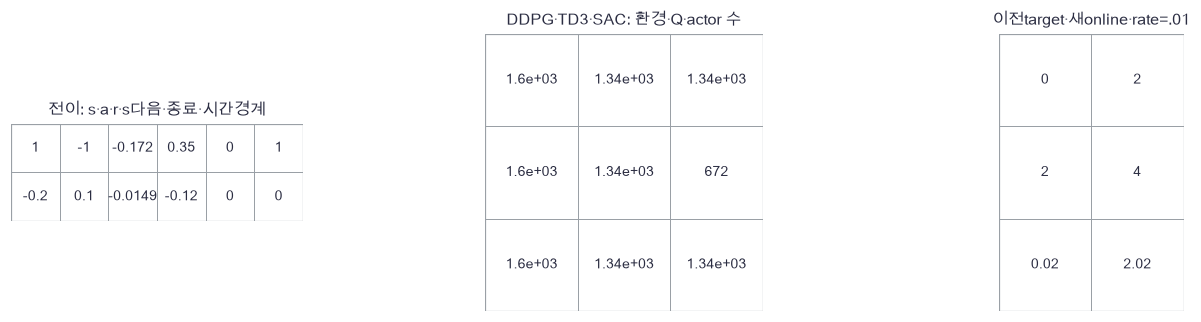

In [35]:
plot_panels([replay_demo,schedule,update_demo],['전이: s·a·r·s다음·종료·시간경계','DDPG·TD3·SAC: 환경·Q·actor 수','이전target·새online·rate=.01'])

🔍 **확인** · 첫 줄은 수집을 끊어도 실제 종료가 아니므로 bootstrap을 유지합니다. 표의 Q 수는 critic 하나당 업데이트 수입니다. TD3·SAC는 두 critic을 각각 갱신합니다.

In [36]:
def adam_step(p,g,m,v,step,lr=.001):
    """Adam .9/.999 모멘트와 bias 보정으로 배열을 갱신합니다."""
    for key in p:
        m[key]=.9*m[key]+.1*g[key]
        v[key]=.999*v[key]+.001*g[key]**2
        p[key]-=lr*(m[key]/(1-.9**step))/(np.sqrt(v[key]/(1-.999**step))+1e-8)

In [37]:
def soft_update(target,online,rate=.01):
    """target←(1−rate)target+rate*online, 여기서 rate는 새 값을 넣는 비율입니다."""
    for key in target:
        target[key]=(1-rate)*target[key]+rate*online[key]

In [38]:
def copy_parameters(p):
    """각 배열의 독립 사본을 만듭니다."""
    return {key:value.copy() for key,value in p.items()}

In [39]:
def zero_state(p):
    """파라미터와 같은 shape의 optimizer0 상태를 만듭니다."""
    return {key:np.zeros_like(value) for key,value in p.items()}

In [40]:
def train_control(method,seed,total_steps=1600,warmup=256):
    """실제 환경 수집→replay→Q→actor→target 순서의 세 연속 제어 알고리즘입니다."""
    # 쓰는 것: actor_loss (3절) · adam_step (4절) · control_step (1절) · critic_loss (3절) · init_mlp (1절) · policy_forward (2절) · td_target (3절)
    # 1. 알고리즘별 actor·Q·target과 독립 난수 흐름을 준비합니다.
    actor=init_mlp(1,2 if method=='SAC' else 1,seed,8)
    critics=[init_mlp(2,1,seed+10,12)]
    if method!='DDPG':
        critics.append(init_mlp(2,1,seed+20,12))
    target_actor=None if method=='SAC' else copy_parameters(actor)
    targets=[copy_parameters(q) for q in critics]
    am,av=zero_state(actor),zero_state(actor)
    qm=[zero_state(q) for q in critics]
    qv=[zero_state(q) for q in critics]
    env_rng=np.random.default_rng(seed+100)
    action_rng=np.random.default_rng(seed+200)
    batch_rng=np.random.default_rng(seed+300)
    target_rng=np.random.default_rng(seed+400)
    replay=np.zeros((total_steps,6))
    state=float(env_rng.uniform(-1.5,1.5))
    actor_steps=0
    history=[]
    # 2. 매 상호작용을 저장하며25step 수집 경계에서는 새 시작 상태를 뽑습니다.
    for step in range(total_steps):
        if step<warmup:
            action=float(action_rng.uniform(-1,1))
        else:
            eps=action_rng.normal(size=(1,1))
            raw_action,_,_=policy_forward(np.array([[state]]),actor,eps,method=='SAC')
            action=float(raw_action[0,0])
            if method!='SAC':
                action=float(np.clip(action+.15*eps[0,0],-1,1))
        next_state,reward=control_step(state,action,float(env_rng.normal(0,.03)))
        truncated=float((step+1)%25==0)
        replay[step]=[state,action,reward,next_state,0.,truncated]
        state=float(env_rng.uniform(-1.5,1.5)) if truncated else float(next_state)
        if step<warmup:
            continue
        # 3. 모든 Q는 동일한 고정 target으로 매 step 갱신합니다.
        update=step-warmup+1
        idx=batch_rng.integers(0,step+1,32)
        batch=replay[idx]
        S,A,R,NS,terminal=[batch[:,j:j+1] for j in range(5)]
        target_noise=target_rng.normal(size=(32,1))
        y=td_target(R,NS,terminal,actor,target_actor,targets,target_noise,method)
        losses=[]
        for j,q in enumerate(critics):
            loss,g,_=critic_loss(S,A,y,q)
            adam_step(q,g,qm[j],qv[j],update)
            losses.append(loss)
        # 4. TD3만 두 Q 갱신에 한 번 actor·target을 갱신합니다.
        if method!='TD3' or update%2==0:
            actor_steps+=1
            loss,g,_=actor_loss(S,actor,critics,action_rng.normal(size=(32,1)),method)
            adam_step(actor,g,am,av,actor_steps)
            for target,q in zip(targets,critics):
                soft_update(target,q)
            if method!='SAC':
                soft_update(target_actor,actor)
        if update%200==0:
            history.append([step+1,np.mean(losses),np.mean(replay[:step+1,2])])
    return actor,critics,np.array(history),replay,actor_steps

In [41]:
# 쓰는 것: det_actor (3절) · probe_q1 (3절) · probe_q2 (3절) · probe_s (3절) · soft_update (4절) · td_target (3절)
constant_q1=zero_state(probe_q1)
constant_q2=zero_state(probe_q2)
constant_q1['c'][:]=2.
constant_q2['c'][:]=3.
zero_actor=zero_state(det_actor)
reward_check=np.array([[-1.],[-1.]])
end_check=np.array([[1.],[0.]])
y_check=td_target(reward_check,probe_s,end_check,zero_actor,zero_actor,[constant_q1,constant_q2],np.zeros_like(probe_s),'TD3')
np.testing.assert_allclose(y_check,[[-1.],[.9]])  # 검산: terminal은r만, truncated 비종료는−1+.95*2
old=copy_parameters(constant_q1)
soft_update(old,constant_q2,.01)
np.testing.assert_allclose(old['c'],[2.01])  # 검산: rate는 새 값의 비율
np.testing.assert_array_equal(constant_q1['c'],[2.])  # 검산: target 사본 갱신이 원본을 바꾸지 않음
print('target 분모·실제 종료·soft update 사본을 확인했습니다.')

target 분모·실제 종료·soft update 사본을 확인했습니다.


In [42]:
methods=['DDPG','TD3','SAC']
training_seeds=[5901,5902]
runs=[]
start=perf_counter()
for method in methods:
    for seed in training_seeds:
        actor,critics,history,replay,actor_steps=train_control(method,seed)
        expected_actor=672 if method=='TD3' else 1344
        assert actor_steps==expected_actor, '알고리즘별 actor 갱신 수가 계획과 같아야 합니다'
        np.testing.assert_array_equal(replay[:,4],0.)  # 검산: 이 환경에는 실제 종료가 없음
        np.testing.assert_equal(replay[:,5].sum(),64)  # 검산: 1600/25 관리상 경계
        np.testing.assert_allclose(replay[:,2],-(replay[:,3]**2+.05*replay[:,1]**2))  # 검산: reset 전 실제 next state가 저장됨
        assert np.max(np.abs(replay[:,1]))<=1., '수집 행동은 범위 안이어야 합니다'
        runs.append((method,seed,actor,critics,history,replay,actor_steps))
print('실제6회 학습 총 초',round(perf_counter()-start,2))

실제6회 학습 총 초 1.39


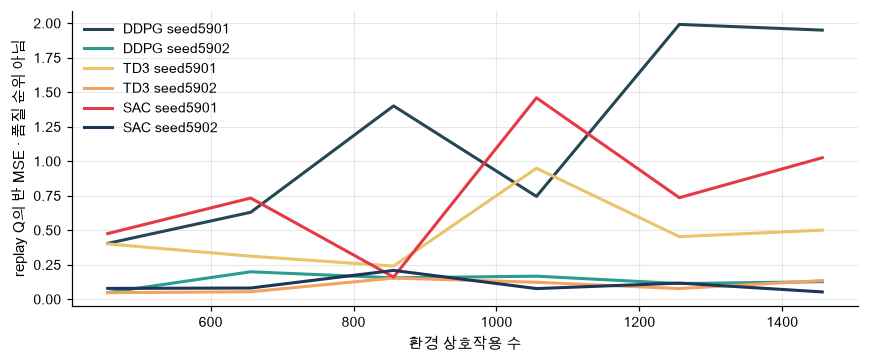

In [43]:
plot_curves([r[4][:,[0,1]] for r in runs],[f'{r[0]} seed{r[1]}' for r in runs],'replay Q의 반 MSE · 품질 순위 아님')

### ✏️ 연습 4 · target의 새 값 비율

느린 target 갱신에서 rate를 online 비율로 사용하세요.

In [44]:
def exercise_target_update(old,online,rate):
    """느린 target 갱신에서 rate를 online 비율로 사용하세요."""

    ### 구현할 내용: 느린 target 갱신에서 rate를 online 비율로 사용하세요.
    raise NotImplementedError
    return new

In [45]:
def check_target_update(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([0.,2.]),np.array([2.,4.]),.01),[.02,2.02])  # 검산: online1%
    print("연습 4: 독립 기준값과 일치합니다.")

run_check(check_target_update,exercise_target_update,hint="느린 target 갱신에서 rate를 online 비율로 사용하세요.")

☐ exercise_target_update: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 느린 target 갱신에서 rate를 online 비율로 사용하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
new = (1-rate)*old+rate*online
```

</details>

## 🔑 5. entropy를 뺀 실제 제어 보상으로 평가합니다

**이 절에서 가져갈 것:** 학습의 확장 목적과 환경 보상을 구분하고 seed·rollout 분모를 분리합니다.

학습이 끝난 정책을 원점 제어에 사용합니다. 공통 독립 seed5990에서32개 시작상태를 uniform[−1.5,1.5]로 만들고 각20 step을 평가합니다. 모든 모델은 같은 환경 잡음 배열을 사용합니다. 이 평가 seed는 학습에 쓰지 않습니다. 보고 값은 $G_i=\sum_{t=0}^{19}.95^t r_{it}$의 episode 평균이며 step 평균이 아닙니다. entropy bonus는 포함하지 않습니다.

SAC는 확률적 rollout과 `tanh(μ)` 사용을 모두 보고합니다. 후자는 tanh 이전 평균을 쓴 행동이며 일반적으로 E[tanh(u)]와 같지 않습니다. DDPG·TD3는 탐색 잡음을 끕니다. 기준선은 a=0과 미리 정한 `clip(−1.3s)` feedback이며 최적 정책이라고 부르지 않습니다.

각 학습 seed의32 episode 평균과 조건부 표준오차 `std(G,ddof=1)/sqrt(32)`를 출력합니다. 두 학습seed는 별도로 표시하므로 rollout수를 학습반복수로 부풀리지 않습니다. 결과 표의 포화율은32×20행동 중 |a|>.95인 비율입니다. 두 seed의 성능 순서를 일반적 우위로 주장하지 않습니다. 작은 critic loss도 좋은 제어를 보장하지 않습니다.

In [46]:
return_examples=np.array([[-1.,-.5,-.25],[-2.,-1.,-.5]])
discount=np.array([1.,.95,.95**2])
episode_returns=(return_examples*discount).sum(axis=1,keepdims=True)
evaluation_plan=np.array([[32.,20.,5990.],[2.,1600.,256.]])

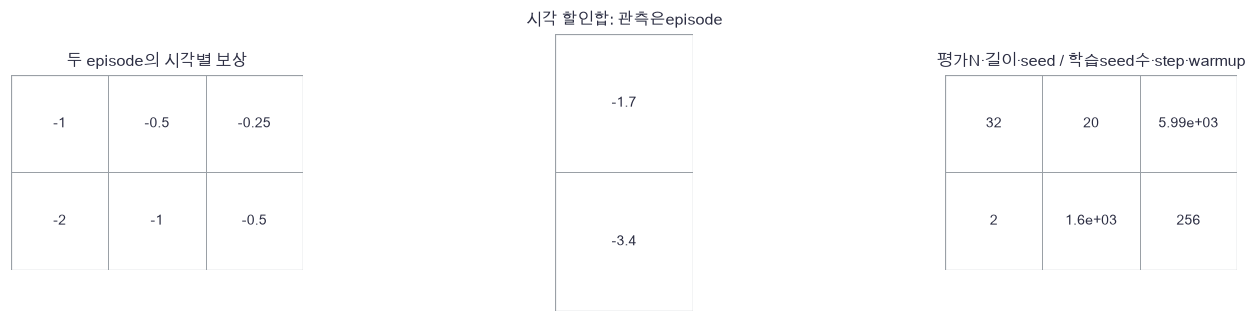

In [47]:
plot_panels([return_examples,episode_returns,evaluation_plan],['두 episode의 시각별 보상','시각 할인합: 관측은episode','평가N·길이·seed / 학습seed수·step·warmup'])

🔍 **확인** · 한 episode가 하나의 반환 표본입니다. 20개 시각 보상은 서로 의존하며 독립 표본20개로 세지 않습니다.

In [48]:
def evaluate_control(actor,method,seed=5990,stochastic=False,episodes=32,horizon=20):
    """고정 시작분포의 독립20step 할인 보상. entropy bonus는 평가 보상에 넣지 않습니다."""
    # 쓰는 것: control_step (1절) · policy_forward (2절)
    env_rng=np.random.default_rng(seed)
    policy_rng=np.random.default_rng(seed+1)
    state=env_rng.uniform(-1.5,1.5,(episodes,1))
    returns=np.zeros(episodes)
    trajectory=[state[:,0].copy()]
    saturation=[]
    for time in range(horizon):
        if method=='zero':
            action=np.zeros_like(state)
        elif method=='feedback':
            action=np.clip(-1.3*state,-1.,1.)
        else:
            noise=policy_rng.normal(size=state.shape) if stochastic else np.zeros_like(state)
            action,_,_=policy_forward(state,actor,noise,method=='SAC')
        state,reward=control_step(state,action,env_rng.normal(0,.03,state.shape))
        returns+=.95**time*reward[:,0]
        trajectory.append(state[:,0].copy())
        saturation.append(np.abs(action)>.95)
    return returns,np.array(trajectory),np.mean(saturation)

In [49]:
# 쓰는 것: runs (4절)
evaluation=[]
labels=[]
traces=[]
for method in ['zero','feedback']:
    returns,trajectory,saturation=evaluate_control(None,method)
    evaluation.append([returns.mean(),returns.std(ddof=1)/np.sqrt(len(returns)),saturation])
    labels.append(method)
    traces.append(trajectory[:,0])
for method,seed,actor,critics,history,replay,actor_steps in runs:
    for stochastic in ([False,True] if method=='SAC' else [False]):
        returns,trajectory,saturation=evaluate_control(actor,method,stochastic=stochastic)
        evaluation.append([returns.mean(),returns.std(ddof=1)/np.sqrt(len(returns)),saturation])
        label=f'{method} {seed} '+('표본' if stochastic else 'tanh평균/결정론')
        labels.append(label)
        if seed==5901 and not stochastic:
            traces.append(trajectory[:,0])
evaluation=np.array(evaluation)
for label,row in zip(labels,evaluation):
    print(label,np.round(row,4))

zero [-2.1882  0.2782  0.    ]
feedback [-0.2332  0.0382  0.0328]
DDPG 5901 tanh평균/결정론 [-19.6905   0.3866   0.0922]
DDPG 5902 tanh평균/결정론 [-1.6236  0.0323  0.0672]
TD3 5901 tanh평균/결정론 [-3.625   0.0354  0.0359]
TD3 5902 tanh평균/결정론 [-6.9627  0.0822  0.0531]
SAC 5901 tanh평균/결정론 [-0.6698  0.0404  0.0016]
SAC 5901 표본 [-1.4381  0.0965  0.0188]
SAC 5902 tanh평균/결정론 [-0.806   0.0734  0.    ]
SAC 5902 표본 [-2.0543e+00  2.1010e-01  1.6000e-03]


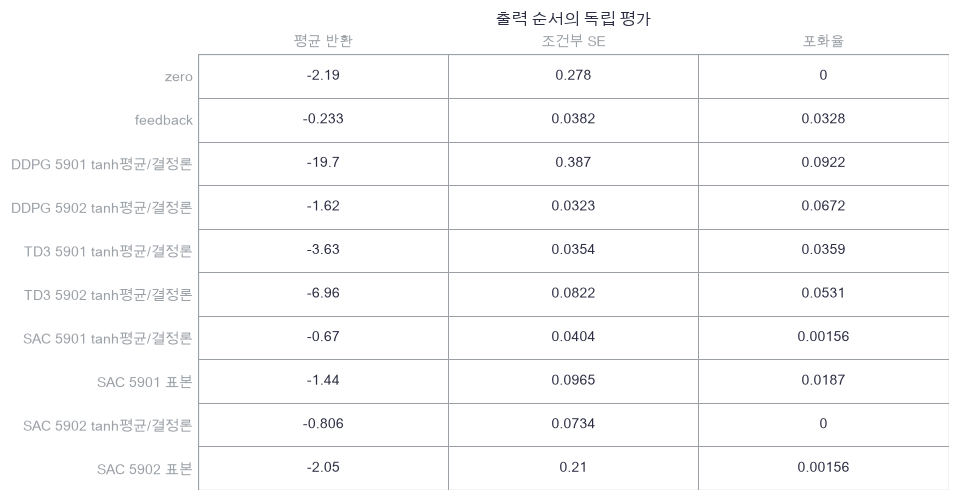

In [50]:
plot_panels([evaluation],['출력 순서의 독립 평가'],[['평균 반환','조건부 SE','포화율']],rows=[labels])

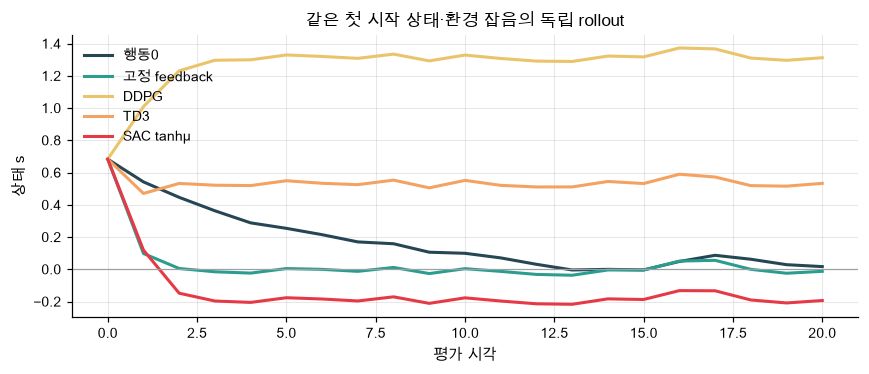

In [51]:
plot_trajectories(np.arange(21),traces,['행동0','고정 feedback','DDPG','TD3','SAC tanhμ'])

In [52]:
# 쓰는 것: runs (4절)
for method,seed,actor,critics,history,replay,actor_steps in runs:
    actor_count=sum(a.size for a in actor.values())
    critic_count=sum(sum(a.size for a in q.values()) for q in critics)
    print(method,seed,'actor/Q 학습 파라미터',actor_count,critic_count,'· actor 갱신',actor_steps)
assert np.isfinite(evaluation).all(), '모든 독립 평가값이 유한해야 합니다'
print('평가 종료: 이후 설정을 다시 고르지 않습니다.')

DDPG 5901 actor/Q 학습 파라미터 25 49 · actor 갱신 1344
DDPG 5902 actor/Q 학습 파라미터 25 49 · actor 갱신 1344
TD3 5901 actor/Q 학습 파라미터 25 98 · actor 갱신 672
TD3 5902 actor/Q 학습 파라미터 25 98 · actor 갱신 672
SAC 5901 actor/Q 학습 파라미터 34 98 · actor 갱신 1344
SAC 5902 actor/Q 학습 파라미터 34 98 · actor 갱신 1344
평가 종료: 이후 설정을 다시 고르지 않습니다.


🔍 **확인** · 위는 고정한 두 학습 seed의 실제 결과입니다. SAC의 확률 행동은 탐색·entropy 목적 때문에 같은 모델의 tanhμ 제어와 보상이 다를 수 있습니다. target noise·두 Q·지연갱신은 수치 안정성을 위한 설계이며 이 작은 환경에서 항상 순위 개선을 보장하지 않습니다. 환경모델을 알고 계획하는60번과 고정 데이터만 쓰는61번은 다른 정보 조건의 문제입니다. 이 실행에서는 행동0의 평균 반환이 약−2.19, 미리 정한 feedback은−.23입니다. DDPG는 두 seed에서−19.69와−1.62, TD3는−3.63과−6.96으로 큰 편차 또는 낮은 성능을 보였습니다. SAC tanhμ는−.67과−.81이지만 feedback 기준선보다 낮습니다. 충분히 좋은 제어를 모두 학습한 결과가 아니며, 고정한 작은 예산의 한계를 그대로 기록합니다.

### ✏️ 연습 5 · episode마다 할인합

rewards:(episodes,time)의 시각축을 할인합하여 episode 반환을 만드세요.

In [53]:
def exercise_discounted_return(rewards,gamma):
    """rewards:(episodes,time)의 시각축을 할인합하여 episode 반환을 만드세요."""
    powers = gamma**np.arange(rewards.shape[1])
    ### 구현할 내용: rewards:(episodes,time)의 시각축을 할인합하여 episode 반환을 만드세요.
    raise NotImplementedError
    return returns

In [54]:
def check_discounted_return(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[1.,2.,4.],[0.,0.,8.]]),.5),[3.,2.])  # 검산: 1+1+1, 0+0+2
    print("연습 5: 독립 기준값과 일치합니다.")

run_check(check_discounted_return,exercise_discounted_return,hint="rewards:(episodes,time)의 시각축을 할인합하여 episode 반환을 만드세요.")

☐ exercise_discounted_return: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: rewards:(episodes,time)의 시각축을 할인합하여 episode 반환을 만드세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
returns = (rewards*powers).sum(axis=1)
```

</details>

## ✏️ 끝 연습 · 정책·두 Q·갱신·평가를 바꿔 검사합니다

### ✏️ 연습 A · entropy를 포함한 다음 가치

SAC의 다음 행동 soft value를 계산하세요.

In [55]:
def exercise_soft_value(q1,q2,logprob,alpha):
    """SAC의 다음 행동 soft value를 계산하세요."""

    ### 구현할 내용: SAC의 다음 행동 soft value를 계산하세요.
    raise NotImplementedError
    return value

In [56]:
def check_soft_value(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([2.,3.]),np.array([1.,4.]),np.array([-2.,1.]),.1),[1.2,2.9])  # 검산: minQ−αlogπ
    print("연습 A: 독립 기준값과 일치합니다.")

run_check(check_soft_value,exercise_soft_value,hint="SAC의 다음 행동 soft value를 계산하세요.")

☐ exercise_soft_value: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: SAC의 다음 행동 soft value를 계산하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
value = np.minimum(q1,q2)-alpha*logprob
```

</details>

### ✏️ 연습 B · 고정 잡음으로 행동 만들기

Gaussian 재매개화 후 tanh 행동을 계산하세요.

In [57]:
def exercise_reparameterization(mean,logstd,noise):
    """Gaussian 재매개화 후 tanh 행동을 계산하세요."""

    ### 구현할 내용: Gaussian 재매개화 후 tanh 행동을 계산하세요.
    raise NotImplementedError
    return action

In [58]:
def check_reparameterization(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([0.,0.]),np.array([0.,np.log(2.)]),np.array([0.,.5])),[0.,np.tanh(1.)])  # 검산: u0와u1
    print("연습 B: 독립 기준값과 일치합니다.")

run_check(check_reparameterization,exercise_reparameterization,hint="Gaussian 재매개화 후 tanh 행동을 계산하세요.")

☐ exercise_reparameterization: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: Gaussian 재매개화 후 tanh 행동을 계산하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
action = np.tanh(mean+np.exp(logstd)*noise)
```

</details>

### ✏️ 연습 C · TD3 actor 갱신 시각

Q 갱신 번호에서 delay마다 actor를 갱신할 위치를 반환하세요.

In [59]:
def exercise_delayed_actor(updates,delay):
    """Q 갱신 번호에서 delay마다 actor를 갱신할 위치를 반환하세요."""

    ### 구현할 내용: Q 갱신 번호에서 delay마다 actor를 갱신할 위치를 반환하세요.
    raise NotImplementedError
    return selected

In [60]:
def check_delayed_actor(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_array_equal(candidate(np.arange(1,7),2),[False,True,False,True,False,True])  # 검산:2·4·6회
    print("연습 C: 독립 기준값과 일치합니다.")

run_check(check_delayed_actor,exercise_delayed_actor,hint="Q 갱신 번호에서 delay마다 actor를 갱신할 위치를 반환하세요.")

☐ exercise_delayed_actor: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: Q 갱신 번호에서 delay마다 actor를 갱신할 위치를 반환하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
selected = updates%delay==0
```

</details>

### ✏️ 연습 D · 독립 episode 평균의 표준오차

하나의 고정 정책에서 독립 episode 반환 평균의 SE를 계산하세요. 학습seed 분산과 다릅니다.

In [61]:
def exercise_episode_se(returns):
    """하나의 고정 정책에서 독립 episode 반환 평균의 SE를 계산하세요. 학습seed 분산과 다릅니다."""

    ### 구현할 내용: 하나의 고정 정책에서 독립 episode 반환 평균의 SE를 계산하세요. 학습seed 분산과 다릅니다.
    raise NotImplementedError
    return se

In [62]:
def check_episode_se(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([1.,3.])),1.)  # 검산: 표본std√2를√2로나누기
    print("연습 D: 독립 기준값과 일치합니다.")

run_check(check_episode_se,exercise_episode_se,hint="하나의 고정 정책에서 독립 episode 반환 평균의 SE를 계산하세요. 학습seed 분산과 다릅니다.")

☐ exercise_episode_se: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 하나의 고정 정책에서 독립 episode 반환 평균의 SE를 계산하세요. 학습seed 분산과 다릅니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
se = returns.std(ddof=1)/np.sqrt(len(returns))
```

</details>

### ✏️ 준비도 질문

- **설명:** DDPG·TD3·SAC가 실제로 바꾸는 target·actor 갱신·탐색은 무엇인가요? → 1–4절
- **수식:** tanh log Jacobian과 고정 noise의 logσ 직접미분, 두Q target·entropy 부호를 쓸 수 있나요? → 2·3절
- **구현:** 모든 actor·critic 배열과 입력을 차분하고 target을 고정하며 TD3 지연횟수를 검사할 수 있나요? → 3·4절
- **변형 검산:** 실제 종료와 시간경계, 행동 포화, entropy 계수, episode·학습seed 분모를 구분하나요? → 4·5절, 연습 A–D

### 📎 원전과 범위

[DDPG, Lillicrap et al.](https://arxiv.org/abs/1509.02971), [TD3, Fujimoto et al.](https://arxiv.org/abs/1802.09477), [SAC, Haarnoja et al.](https://arxiv.org/abs/1801.01290)을 작은1차원 다단계 환경에서 구현했습니다. [후속 SAC 알고리즘 논문](https://arxiv.org/abs/1812.05905)의 두 target Q와 현재 actor로 soft target을 만드는 형태를 쓰며 별도 V모델·자동 α조정은 넣지 않습니다. 실제 상호작용·replay·전체미분·target 갱신은 모두 본문에 있습니다. 큰 연속제어 benchmark나 일반 성능 우위를 재현한 실험은 아닙니다.